Task 1: Temperature
First request the daily mean air temperture for all of 2025.
The specifications you will need for this is:
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}
Otherwise you can follow the example from frost.met.no on how to get the data
when using Python
10/3/26, 10:54 AM deliverable_1
file:///C:/Users/tutor5923/Documents/inf201-h26-my-repo/deliverables/deliverable_1/deliverable_1.html 1/3
Make a nicely formatted plot of this air temperature, where time is on the x-axis and
temperature is on the y-axis
Create a nicely formatted summary table containing mean, median, min and max
temperature for this year, and display it with print()

5fc771f3-aa29-4adb-bd94-b8415d6cb421
   max_temp  min_temp  mean_temp  median_temp
0      24.5     -16.1   7.903571         8.35


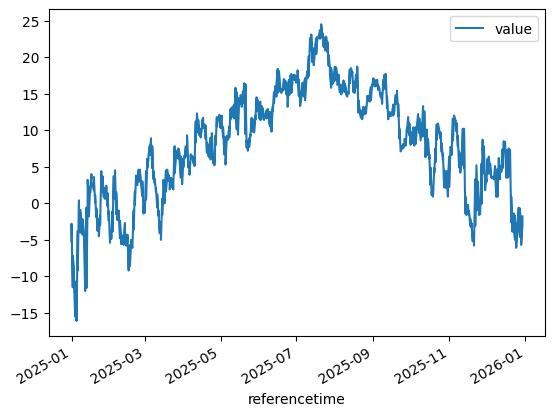

In [219]:
import requests
import os
import pandas as pd
import json
from dotenv import load_dotenv

load_dotenv()
client_id = os.getenv("client_id")
print(client_id)

endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

frost_response = requests.get(endpoint, parameters, auth=(client_id, ""))
json_data = frost_response.json()
data = json_data["data"]

# print(json.dumps(json_data, indent=4))

values = pd.DataFrame()

frames = []
for e in range(len(data)):
    row = pd.DataFrame(data[e]["observations"])
    row["referencetime"] = pd.to_datetime(data[e]["referenceTime"])
    row["sources"] = data[e]["sourceId"]
    frames.append(row)
values = pd.concat(frames, ignore_index=True)
# print(values)

# values.plot()
values.plot(x="referencetime", y="value")


df = pd.DataFrame(
    columns=["max_temp", "min_temp", "mean_temp", "median_temp"],
    data=[[values["value"].max(), values["value"].min(), values["value"].mean(), values["value"].median()]]
)

print(df)


Task 2: Precipitation
Request data for precipitation for the same time period, specifically measurements
of precipitation over 24 hours. This is coded as sum(precipitation_amount
P1D) in the database
Create a new plot that shows both the temperature from task 1 and the precipitation
in the same plot
Think through how to display both values in a way that is useful and looks good
Consider which type of plot works best for each measurement (scatter, line, bar,
pie chart, ...?)

Text(0, 0.5, 'mean temperature (Celsius)')

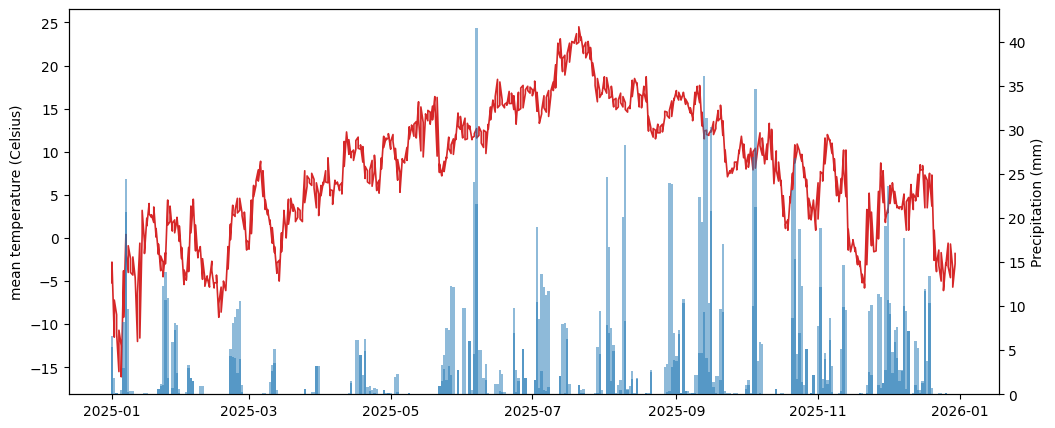

In [ ]:
import datetime as dt

import matplotlib.pyplot as plt


endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters_precip = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

precip_response = requests.get(endpoint, parameters_precip, auth=(client_id, ""))
json_data_precip = precip_response.json()
data_precip = json_data_precip["data"]

# print(json.dumps(json_data_precip, indent=4))

values_precip = pd.DataFrame()

fig, ax = plt.subplots(figsize=(12, 5))

frames_historic = []
for e in range(len(data_precip)):
    row = pd.DataFrame(data_precip[e]["observations"])
    row["referencetime"] = pd.to_datetime(data[e]["referenceTime"])
    # print(row["referencetime"])
    row["sources"] = data_precip[e]["sourceId"]
    frames_historic.append(row)
values_precip = pd.concat(frames_historic, ignore_index=True)

ax2 = ax.twinx()
ax2.bar(values_precip["referencetime"], values_precip["value"],
        width=1, color="tab:blue", alpha=0.5, label="Precipitation")
ax2.set_ylabel("Precipitation (mm)")

ax.plot(values["referencetime"], values["value"],
        color="tab:red", linewidth=1.2, label="Air temperature")
ax.set_ylabel("mean temperature (Celsius)")


Task 3: Historical temperature data
Now you want to compare the 2025 temperatures to temperatures measured 100
years earlier.
Get these temperatures from the database.
Plot the new and the old temperatures in the same plot, still nicely formatted
Generate a summary table as for task 1, where you display data from both the new
and the old temperatures.

<Axes: xlabel='date_no_year'>

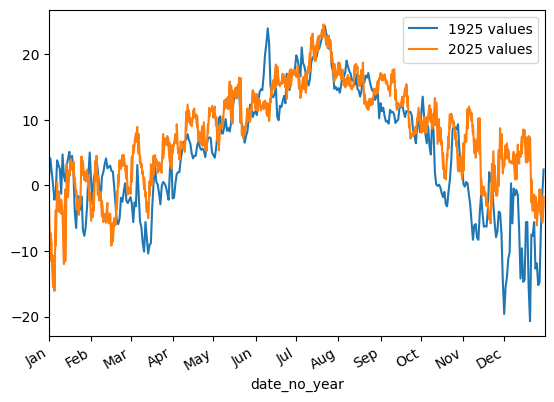

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime as dt


endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters_historic = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D) ",
    "referencetime": "1925-01-01/1925-12-31",
}

historic_response = requests.get(endpoint, parameters_historic, auth=(client_id, ""))
json_historic_data = historic_response.json()
data_historic = json_historic_data["data"]

# print(json.dumps(json_data, indent=4))

historic_values = pd.DataFrame()

frames_historic = []
for e in range(len(data_historic)):
    row = pd.DataFrame(data_historic[e]["observations"])
    row["referencetime"] = pd.to_datetime(data_historic[e]["referenceTime"])
    row["sources"] = data_historic[e]["sourceId"]
    frames_historic.append(row)
historic_values = pd.concat(frames_historic, ignore_index=True)

values['date_no_year'] = pd.to_datetime(
    {'year': 2000, 'month': values['referencetime'].dt.month, 'day': values['referencetime'].dt.day}
)
historic_values['date_no_year'] = pd.to_datetime(
    {'year': 2000, 'month': historic_values['referencetime'].dt.month, 'day': historic_values['referencetime'].dt.day}
)

ax = plt.subplot()

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

historic_values.plot(x="date_no_year", y="value", ax=ax, label="1925 values", xlim=("2000-01-01", "2000-12-31"))
values.plot(x="date_no_year", y="value", ax=ax, label="2025 values", xlim=("2000-01-01", "2000-12-31"))


Task 4: Heatwaves
In this task we can observe that there was one heatwave in Ås in the given year. When other years were tried using this program, it looked like the amount of heatwves withhin the year hasn't changed much. The mean air temperature may not have gone through drastic changes within the last years. 

In [ ]:
def heat_wave_finder(station_id: str, year: int):
    """The function finds the start aand end of a heatwave for a given station and year.
    It the puts the impormation into a yml-file"""

    # Opens a yml-file, and deletes the existing file if there is one
    with open("heat_wave.yml", mode="w+") as f:
        # Sends a get-request the wanted station-realted information from the Frost-site and decodes it
        station_endpoint = f"https://frost.met.no/sources/v0.jsonld?ids={station_id}"
        station_response = requests.get(station_endpoint, auth=(client_id, ""))
        json_station_data = station_response.json()
        station_name = json_station_data["data"][0]["name"]

        # Retrives the wanted information and puts it in a dictionary
        endpoint = "https://frost.met.no/observations/v0.jsonld"
        parameters_heat_wave = {
            "sources": station_id,
            "elements": "max(air_temperature P1D)",
            "referencetime": f"{year}-01-01/{year}-12-31",
        }

        # Sends a get-request to Frost for the wanted information and decodes it
        heat_wave_response = requests.get(endpoint, parameters_heat_wave, auth=(client_id, ""))
        json_heat_wave_data = heat_wave_response.json()
        data_heat_wave = json_heat_wave_data["data"]

        # Keep track of the relevant dates of the heat wave, stationID and name
        HEAT_WAVE_THRESHOLD = 27
        day_counter = 0
        f.write("dates: \n")

        # Goes through every element in data_heat_wave, and sets the today_is_heat_wave_day variable as False
        for item in data_heat_wave:
            today_is_heat_wave_day = False

            for observation in item["observations"]:
                # Checks if todays value is above the threshold, if so today_is_heat_wave_day is set as True
                if float(observation["value"]) >= HEAT_WAVE_THRESHOLD:
                    today_is_heat_wave_day = True
                    break
            if today_is_heat_wave_day:
                day_counter += 1
            else:
                if day_counter >= 5:
                    # Coverts the date in item to a datetime
                    current_date = pd.to_datetime(item["referenceTime"])
                    # end date: today - 1
                    end_date = current_date - pd.Timedelta(days=1)
                    # start date: today - counter
                    start_date = current_date - pd.Timedelta(days=(day_counter))
                    # Writes the date-interval to the file
                    f.write(f"- {start_date} - {end_date} \n")
                # If the counter is less than 5 after today_is_heat_wave_day = False, it is reset
                day_counter = 0

        # Writes the station id, placename and year to the file
        f.write(f"""station_id: {station_id}
station_name: {station_name}
year: {year}""")


# Calls the function with the wanted parameters for this task
heat_wave_finder("SN17850", 2025)

Task 5: Moving average temperature
This smoothes out the the graph to some degree. We can generally conclude that the temperature is at it highest during the summer-months, wich is not very surprising. We can also see that the temperature varies a fair bit within a single month, but has a almost bell curve shape.

<Axes: xlabel='referencetime', ylabel='value'>

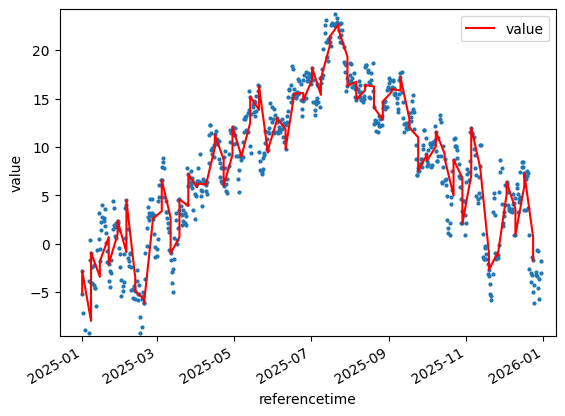

In [263]:
# Retrives the wanted information and puts it in a dictionary
endpoint_avg = "https://frost.met.no/observations/v0.jsonld"
parameters_avg = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

# Sends a get-request to Frost for the wanted information and decodes it
response_avg = requests.get(endpoint_avg, parameters_avg, auth=(client_id, ""))
json_data_avg = response_avg.json()
data_avg = json_data_avg["data"]

# Creates a dataframe
values_avg = pd.DataFrame()

frames_moving_avg = []
avg_values = []
frames_avg = []

# Retrives the wanted information and appends it to two lists
for e in range(len(data_avg)):
    # Retrives the relevant information from data_avg and appends it to a list
    row = pd.DataFrame(data_avg[e]["observations"])
    row["referencetime"] = pd.to_datetime(data_avg[e]["referenceTime"])
    row["sources"] = data_avg[e]["sourceId"]
    frames_avg.append(row)

    # Retrives the relevant information, appends it to a list, and calculates the last seven day moving average
    val = data_avg[e]["observations"][0]["value"]
    avg_values.append(val)
    last_seven = avg_values[-7:]
    last_seven_avg = sum(last_seven) / len(last_seven)

    # Appends the seven day moving average to a list
    data_avg[e]["observations"][0]["value"] = last_seven_avg
    avg_row = pd.DataFrame(data_avg[e]["observations"])
    avg_row["referencetime"] = pd.to_datetime(data_avg[e]["referenceTime"])
    avg_row["sources"] = data_avg[e]["sourceId"]
    frames_moving_avg.append(avg_row)
    seven_day_moving_avg = frames_moving_avg[::7]

# Combines several dataframes
values_avg = pd.concat(frames_avg, ignore_index=True)
moving_values = pd.concat(seven_day_moving_avg, ignore_index=True)

# Plots the values
ax = plt.subplot()
values_avg.plot.scatter(x="referencetime", y="value", s=4, ax=ax)
moving_values.plot(x="referencetime", y="value", ax=ax, color="red")


AI usage
1	How do I pretty-print print(json)?	
Use json.dumps(data, indent=4). print(json) only prints the module object. pprint also works for dicts and lists.

2	What is wrong with the code?	
The notebook was empty on disk at first, so you saved it. The main bug was values.add(row), which does arithmetic and doesn't append. Use pd.concat. Smaller issues were an unconfigured values.plot(), string dates, no status check, and the client ID exposed in the notebook.

3	How do I remove the time from a date?	
Use .dt.date for a date object or .dt.normalize() to keep the datetime dtype.

4	Can that be done in the plot function?
Not in the data, but you can format the axis with mdates.DateFormatter.

5	How do I format a DataFrame table nicely?	
Since the task says to use print(): to_string(index=False, float_format=...), to_markdown() (needs tabulate), or a labelled DataFrame.

6	How do I group values for a bar graph?	
groupby(df['referencetime'].dt.month)['value'].mean().plot.bar(). Other options were resample, pd.cut and weekly or quarterly groups.

7	How do I plot two DataFrames in the same plot?	
Pass the same ax to both calls, with a label= for each. Or combine them into one DataFrame. Use twinx() for different scales.
8	How do I combine a bar chart and a time series?	
Use matplotlib's ax.bar and ax.plot on date x-values. Pandas bar plots use positions, not dates.
9	How do I make a figure with two graphs and different x-axes (data is JSON)?	
Convert the JSON to DataFrames, then use plt.subplots(2, 1). twiny() is the option for two x-axes on one panel, though it's rarely the right choice.

10	How do I plot data when one x is datetime and the other is 1 to 12?	
Convert the months to dates (mid-month) so both share one axis, or use separate subplots.

11	"cannot unpack non-iterable Axes object"	
plt.subplots() with one panel returns a single Axes. Ask for two panels, or use ax = df.plot() and not fig, ax = df.plot().

12	"subplot() takes 1 or 3 positional arguments"	
You used plt.subplot (singular). Use plt.subplots (plural), or give subplot three arguments.

13	How do I put two DataFrames in one plot? (again)	
I repeated the answer to question 7 more briefly.

14	How do I strip the year from a datetime?	
A datetime always has a year. Use strftime('%m-%d'), .dt.month and .dt.day, replace(year=2000), or format only the axis.

15	"'DataFrame' object has no attribute 'xaxis'"	
ax held a DataFrame, not an Axes. Create it with fig, ax = plt.subplots() or ax = df.plot() right before formatting.

16	How do I strip the year from dates in a Series/DataFrame? (again)	
I repeated the answer to question 14, using the .dt accessor.

17	How do I get values and values_precip into the same plot?	
Temperature as a line on the left axis and precipitation as bars on a twinx() right axis. I found a bug in your notebook: the precipitation loop used data[e] instead of data_precip[e].

18	Why don't the historic and current values render properly?	
colour= should be color=. strftime("%m") also turns the dates into month strings, so use a datetime with a dummy year and format the axis instead.

19	How do I show only the month on the x-axis label?	
MonthLocator() with DateFormatter('%b'). This needs real datetimes, not strings.

20	How do I push code to the GitHub repo?	
git init, add the remote, commit and push. Remove the client ID from the notebook first. Watch out for authentication, branch names and OneDrive conflicts.

22	How do I get a datetime from a string?	
pd.to_datetime(...), with format= or errors='coerce' if needed, or datetime.strptime for a single string.

23	How do I subtract a day from a date?	
Subtract pd.Timedelta(days=1) or timedelta(days=1). Use DateOffset for months and years.

24	What is w+ mode?	
A file mode for read and write that truncates (erases) an existing file. I compared it with the r, r+, w, a and x modes.

25	What does pd.concat do?	
Stacks DataFrames by rows (default) or places them side by side with axis=1. Use ignore_index=True and pass a list.

26	How do I append only every seventh avg_row?	
Use enumerate with (i + 1) % 7 == 0, or slice with [6::7]. For weekly averages, use resample('W') or group by blocks of 7.